In [1]:
import os
import sys
import time
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Torch Version:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))


Torch Version: 2.11.0+cu128
Device: cuda
GPU Name: Tesla T4


In [2]:
m = 6
n = 3
dt = 0.1

F_mat = torch.tensor([
    [1.0, 0.0, 0.0,  dt, 0.0, 0.0],
    [0.0, 1.0, 0.0, 0.0,  dt, 0.0],
    [0.0, 0.0, 1.0, 0.0, 0.0,  dt],
    [0.0, 0.0, 0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 1.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 1.0]
], dtype=torch.float32)

H_mat = torch.tensor([
    [1.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 1.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
], dtype=torch.float32)

q_var = 0.5
r_var = 1.0

Q_mat = q_var * torch.tensor([
    [(dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0,        0.0,        0.0],
    [       0.0, (dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0,        0.0],
    [       0.0,        0.0, (dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0],
    [(dt**2)/2.0,        0.0,        0.0,          dt,        0.0,        0.0],
    [       0.0, (dt**2)/2.0,        0.0,        0.0,          dt,        0.0],
    [       0.0,        0.0, (dt**2)/2.0,        0.0,        0.0,          dt]
], dtype=torch.float32) + 1e-6 * torch.eye(m)

R_mat = r_var * torch.eye(n, dtype=torch.float32)

q_mismatch = 10.0 * q_var
r_mismatch = 10.0 * r_var
Q_mismatched = q_mismatch * torch.tensor([
    [(dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0,        0.0,        0.0],
    [       0.0, (dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0,        0.0],
    [       0.0,        0.0, (dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0],
    [(dt**2)/2.0,        0.0,        0.0,          dt,        0.0,        0.0],
    [       0.0, (dt**2)/2.0,        0.0,        0.0,          dt,        0.0],
    [       0.0,        0.0, (dt**2)/2.0,        0.0,        0.0,          dt]
], dtype=torch.float32) + 1e-6 * torch.eye(m)

R_mismatched = r_mismatch * torch.eye(n, dtype=torch.float32)


In [3]:
def generate_uav_trajectory(num_sequences, sequence_length, dt, q_val, r_val, nonlinear_maneuver=True):
    torch.manual_seed(42)
    np.random.seed(42)
    X = torch.zeros((num_sequences, sequence_length, m), dtype=torch.float32)
    Y = torch.zeros((num_sequences, sequence_length, n), dtype=torch.float32)
    
    Q_chol = torch.linalg.cholesky(q_val * torch.tensor([
        [(dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0,        0.0,        0.0],
        [       0.0, (dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0,        0.0],
        [       0.0,        0.0, (dt**3)/3.0,        0.0,        0.0, (dt**2)/2.0],
        [(dt**2)/2.0,        0.0,        0.0,          dt,        0.0,        0.0],
        [       0.0, (dt**2)/2.0,        0.0,        0.0,          dt,        0.0],
        [       0.0,        0.0, (dt**2)/2.0,        0.0,        0.0,          dt]
    ], dtype=torch.float32) + 1e-6 * torch.eye(m))
    
    R_chol = torch.sqrt(torch.tensor(r_val, dtype=torch.float32)) * torch.eye(n)
    
    for i in range(num_sequences):
        x_curr = torch.tensor([
            np.random.uniform(-10.0, 10.0),
            np.random.uniform(-10.0, 10.0),
            np.random.uniform(5.0, 20.0),
            np.random.uniform(-2.0, 2.0),
            np.random.uniform(-2.0, 2.0),
            np.random.uniform(-0.5, 0.5)
        ], dtype=torch.float32)
        
        t_eval = torch.arange(sequence_length) * dt
        for t in range(sequence_length):
            w = torch.matmul(Q_chol, torch.randn(m, dtype=torch.float32))
            if nonlinear_maneuver:
                time_sec = float(t_eval[t])
                a_drag_x = -0.05 * x_curr[3] * torch.abs(x_curr[3])
                a_drag_y = -0.05 * x_curr[4] * torch.abs(x_curr[4])
                a_centripetal = 1.2 * torch.sin(torch.tensor(0.5 * time_sec, dtype=torch.float32))
                maneuver = torch.tensor([0.0, 0.0, 0.0, a_drag_x + a_centripetal, a_drag_y, 0.0], dtype=torch.float32)
                x_next = torch.matmul(F_mat, x_curr) + maneuver * dt + w
            else:
                x_next = torch.matmul(F_mat, x_curr) + w
            
            v = torch.matmul(R_chol, torch.randn(n, dtype=torch.float32))
            y_curr = torch.matmul(H_mat, x_next) + v
            
            X[i, t] = x_next
            Y[i, t] = y_curr
            x_curr = x_next
            
    return X, Y

X_train, Y_train = generate_uav_trajectory(250, 100, dt, q_var, r_var, True)
X_val, Y_val = generate_uav_trajectory(50, 100, dt, q_var, r_var, True)
X_test, Y_test = generate_uav_trajectory(60, 100, dt, q_var, r_var, True)

print("Train X shape:", X_train.shape, "Y shape:", Y_train.shape)
print("Val X shape:", X_val.shape, "Y shape:", Y_val.shape)
print("Test X shape:", X_test.shape, "Y shape:", Y_test.shape)


Train X shape: torch.Size([250, 100, 6]) Y shape: torch.Size([250, 100, 3])
Val X shape: torch.Size([50, 100, 6]) Y shape: torch.Size([50, 100, 3])
Test X shape: torch.Size([60, 100, 6]) Y shape: torch.Size([60, 100, 3])


In [4]:
class ClassicalKalmanFilter:
    def __init__(self, F_matrix, H_matrix, Q_matrix, R_matrix):
        self.F = F_matrix
        self.H = H_matrix
        self.Q = Q_matrix
        self.R = R_matrix
        self.m = F_matrix.shape[0]
        self.n = H_matrix.shape[0]

    def filter_sequence(self, Y_seq, x0=None, P0=None):
        T_steps = Y_seq.shape[0]
        device = Y_seq.device
        F = self.F.to(device)
        H = self.H.to(device)
        Q = self.Q.to(device)
        R = self.R.to(device)
        
        x_est = torch.zeros((T_steps, self.m), device=device)
        KG_history = torch.zeros((T_steps, self.m, self.n), device=device)
        
        if x0 is None:
            x_post = torch.zeros(self.m, device=device)
            x_post[:self.n] = Y_seq[0]
        else:
            x_post = x0.clone().to(device)
            
        if P0 is None:
            P_post = torch.eye(self.m, device=device) * 1.0
        else:
            P_post = P0.clone().to(device)
            
        for t in range(T_steps):
            x_prior = torch.matmul(F, x_post)
            P_prior = torch.matmul(torch.matmul(F, P_post), F.t()) + Q
            
            y_pred = torch.matmul(H, x_prior)
            y_obs = Y_seq[t]
            dy = y_obs - y_pred
            
            S = torch.matmul(torch.matmul(H, P_prior), H.t()) + R
            S_inv = torch.linalg.inv(S)
            K = torch.matmul(torch.matmul(P_prior, H.t()), S_inv)
            
            x_post = x_prior + torch.matmul(K, dy)
            P_post = torch.matmul(torch.eye(self.m, device=device) - torch.matmul(K, H), P_prior)
            
            x_est[t] = x_post
            KG_history[t] = K
            
        return x_est, KG_history

    def filter_batch(self, Y_batch):
        B, T_steps, _ = Y_batch.shape
        X_est = torch.zeros((B, T_steps, self.m), device=Y_batch.device)
        for b in range(B):
            X_est[b], _ = self.filter_sequence(Y_batch[b])
        return X_est


In [5]:
def F_norm(tensor_val):
    return F.normalize(tensor_val, p=2, dim=1, eps=1e-12)

class KalmanNetNN(nn.Module):
    def __init__(self, F_matrix, H_matrix, in_mult=5, out_mult=8):
        super().__init__()
        self.F = F_matrix
        self.H = H_matrix
        self.m = F_matrix.shape[0]
        self.n = H_matrix.shape[0]
        self.in_mult = in_mult
        self.out_mult = out_mult
        
        self.d_input_Q = self.m * in_mult
        self.d_hidden_Q = self.m ** 2
        self.GRU_Q = nn.GRU(self.d_input_Q, self.d_hidden_Q, batch_first=True)
        
        self.d_input_Sigma = self.d_hidden_Q + self.m * in_mult
        self.d_hidden_Sigma = self.m ** 2
        self.GRU_Sigma = nn.GRU(self.d_input_Sigma, self.d_hidden_Sigma, batch_first=True)
        
        self.d_input_S = self.n ** 2 + 2 * self.n * in_mult
        self.d_hidden_S = self.n ** 2
        self.GRU_S = nn.GRU(self.d_input_S, self.d_hidden_S, batch_first=True)
        
        self.FC1 = nn.Sequential(
            nn.Linear(self.d_hidden_Sigma, self.n ** 2),
            nn.ReLU()
        )
        
        self.d_input_FC2 = self.d_hidden_Sigma + self.d_hidden_S
        self.d_hidden_FC2 = self.d_input_FC2 * out_mult
        self.d_output_FC2 = self.m * self.n
        self.FC2 = nn.Sequential(
            nn.Linear(self.d_input_FC2, self.d_hidden_FC2),
            nn.ReLU(),
            nn.Linear(self.d_hidden_FC2, self.d_output_FC2)
        )
        
        self.FC3 = nn.Sequential(
            nn.Linear(self.d_hidden_S + self.d_output_FC2, self.m ** 2),
            nn.ReLU()
        )
        
        self.FC4 = nn.Sequential(
            nn.Linear(self.d_hidden_Sigma + self.m ** 2, self.d_hidden_Sigma),
            nn.ReLU()
        )
        
        self.FC5 = nn.Sequential(
            nn.Linear(self.m, self.m * in_mult),
            nn.ReLU()
        )
        
        self.FC6 = nn.Sequential(
            nn.Linear(self.m, self.m * in_mult),
            nn.ReLU()
        )
        
        self.FC7 = nn.Sequential(
            nn.Linear(2 * self.n, 2 * self.n * in_mult),
            nn.ReLU()
        )
        
        self.prior_Q = torch.eye(self.m)
        self.prior_Sigma = torch.eye(self.m)
        self.prior_S = torch.eye(self.n)

    def init_hidden(self, batch_size, device):
        self.h_Q = self.prior_Q.to(device).flatten().unsqueeze(0).unsqueeze(0).repeat(1, batch_size, 1)
        self.h_Sigma = self.prior_Sigma.to(device).flatten().unsqueeze(0).unsqueeze(0).repeat(1, batch_size, 1)
        self.h_S = self.prior_S.to(device).flatten().unsqueeze(0).unsqueeze(0).repeat(1, batch_size, 1)

    def step_KGain(self, obs_diff, obs_innov_diff, fw_evol_diff, fw_update_diff, batch_size):
        in_FC5 = fw_update_diff.unsqueeze(1)
        out_FC5 = self.FC5(in_FC5)
        
        out_Q, self.h_Q = self.GRU_Q(out_FC5, self.h_Q)
        
        in_FC6 = fw_evol_diff.unsqueeze(1)
        out_FC6 = self.FC6(in_FC6)
        
        in_Sigma = torch.cat((out_Q, out_FC6), dim=2)
        out_Sigma, self.h_Sigma = self.GRU_Sigma(in_Sigma, self.h_Sigma)
        
        out_FC1 = self.FC1(out_Sigma)
        
        obs_cat = torch.cat((obs_diff, obs_innov_diff), dim=1).unsqueeze(1)
        out_FC7 = self.FC7(obs_cat)
        
        in_S = torch.cat((out_FC1, out_FC7), dim=2)
        out_S, self.h_S = self.GRU_S(in_S, self.h_S)
        
        in_FC2 = torch.cat((out_Sigma, out_S), dim=2)
        out_FC2 = self.FC2(in_FC2)
        
        in_FC3 = torch.cat((out_S, out_FC2), dim=2)
        out_FC3 = self.FC3(in_FC3)
        
        in_FC4 = torch.cat((out_Sigma, out_FC3), dim=2)
        out_FC4 = self.FC4(in_FC4)
        
        self.h_Sigma = out_FC4.transpose(0, 1)
        
        KGain = out_FC2.view(batch_size, self.m, self.n)
        return KGain

    def forward_sequence(self, Y_seq):
        batch_size, seq_len, _ = Y_seq.shape
        device = Y_seq.device
        self.init_hidden(batch_size, device)
        
        F = self.F.to(device).unsqueeze(0).repeat(batch_size, 1, 1)
        H = self.H.to(device).unsqueeze(0).repeat(batch_size, 1, 1)
        
        X_est = torch.zeros((batch_size, seq_len, self.m), device=device)
        KG_est = torch.zeros((batch_size, seq_len, self.m, self.n), device=device)
        
        x_post = torch.zeros((batch_size, self.m, 1), device=device)
        x_post[:, :self.n, 0] = Y_seq[:, 0, :]
        x_post_prev = x_post.clone()
        x_prior_prev = x_post.clone()
        y_prev = torch.bmm(H, x_post)
        
        for t in range(seq_len):
            y_curr = Y_seq[:, t, :].unsqueeze(2)
            
            x_prior = torch.bmm(F, x_post)
            y_prior = torch.bmm(H, x_prior)
            
            obs_diff = (y_curr - y_prev).squeeze(2)
            obs_innov_diff = (y_curr - y_prior).squeeze(2)
            fw_evol_diff = (x_post - x_post_prev).squeeze(2)
            fw_update_diff = (x_post - x_prior_prev).squeeze(2)
            
            obs_diff = F_norm(obs_diff)
            obs_innov_diff = F_norm(obs_innov_diff)
            fw_evol_diff = F_norm(fw_evol_diff)
            fw_update_diff = F_norm(fw_update_diff)
            
            KGain = self.step_KGain(obs_diff, obs_innov_diff, fw_evol_diff, fw_update_diff, batch_size)
            
            dy = y_curr - y_prior
            inov = torch.bmm(KGain, dy)
            
            x_post_prev = x_post.clone()
            x_prior_prev = x_prior.clone()
            x_post = x_prior + inov
            y_prev = y_curr.clone()
            
            X_est[:, t, :] = x_post.squeeze(2)
            KG_est[:, t, :, :] = KGain
            
        return X_est, KG_est


In [6]:
def train_kalmannet(model, X_train, Y_train, X_val, Y_val, epochs=40, batch_size=16, lr=1e-3, wd=1e-4):
    device = next(model.parameters()).device
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    loss_fn = nn.MSELoss()
    
    num_train = X_train.shape[0]
    train_losses = []
    val_losses_dB = []
    
    best_val_loss = float('inf')
    best_state_dict = None
    
    for epoch in range(1, epochs + 1):
        model.train()
        indices = torch.randperm(num_train)
        epoch_loss = 0.0
        num_batches = 0
        
        for start_idx in range(0, num_train, batch_size):
            end_idx = min(start_idx + batch_size, num_train)
            batch_idx = indices[start_idx:end_idx]
            batch_X = X_train[batch_idx].to(device)
            batch_Y = Y_train[batch_idx].to(device)
            
            optimizer.zero_grad()
            X_pred, _ = model.forward_sequence(batch_Y)
            loss = loss_fn(X_pred, batch_X)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
            num_batches += 1
            
        avg_train_loss = epoch_loss / num_batches
        train_losses.append(avg_train_loss)
        
        model.eval()
        with torch.no_grad():
            val_X = X_val.to(device)
            val_Y = Y_val.to(device)
            val_pred, _ = model.forward_sequence(val_Y)
            val_mse = loss_fn(val_pred, val_X).item()
            val_dB = 10.0 * np.log10(val_mse)
            val_losses_dB.append(val_dB)
            scheduler.step(val_mse)
            
            if val_mse < best_val_loss:
                best_val_loss = val_mse
                best_state_dict = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                
        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoch {epoch:02d}/{epochs:02d} | Train MSE: {avg_train_loss:.5f} | Val MSE: {val_mse:.5f} | Val MSE (dB): {val_dB:.2f} dB")
            
    if best_state_dict is not None:
        model.load_state_dict({k: v.to(device) for k, v in best_state_dict.items()})
        
    return train_losses, val_losses_dB


In [7]:
knet_model = KalmanNetNN(F_mat, H_mat, in_mult=5, out_mult=8).to(device)
train_losses, val_losses_dB = train_kalmannet(
    knet_model, 
    X_train, 
    Y_train, 
    X_val, 
    Y_val, 
    epochs=40, 
    batch_size=16, 
    lr=1e-3, 
    wd=1e-4
)


Epoch 01/40 | Train MSE: 502502.79104 | Val MSE: 0.45991 | Val MSE (dB): -3.37 dB


Epoch 05/40 | Train MSE: 0.40367 | Val MSE: 0.40139 | Val MSE (dB): -3.96 dB


Epoch 10/40 | Train MSE: 0.38750 | Val MSE: 0.38875 | Val MSE (dB): -4.10 dB


Epoch 15/40 | Train MSE: 0.34717 | Val MSE: 0.35173 | Val MSE (dB): -4.54 dB


Epoch 20/40 | Train MSE: 0.33748 | Val MSE: 0.33916 | Val MSE (dB): -4.70 dB


Epoch 25/40 | Train MSE: 0.32555 | Val MSE: 0.32907 | Val MSE (dB): -4.83 dB


Epoch 30/40 | Train MSE: 0.31979 | Val MSE: 0.31551 | Val MSE (dB): -5.01 dB


Epoch 35/40 | Train MSE: 0.30927 | Val MSE: 0.30809 | Val MSE (dB): -5.11 dB


Epoch 40/40 | Train MSE: 0.30179 | Val MSE: 0.29898 | Val MSE (dB): -5.24 dB


In [8]:
kf_true = ClassicalKalmanFilter(F_mat, H_mat, Q_mat, R_mat)
kf_mismatched = ClassicalKalmanFilter(F_mat, H_mat, Q_mismatched, R_mismatched)

test_X = X_test.to(device)
test_Y = Y_test.to(device)

knet_model.eval()
with torch.no_grad():
    knet_pred, knet_KG = knet_model.forward_sequence(test_Y)

kf_true_pred = kf_true.filter_batch(test_Y)
kf_mismatch_pred = kf_mismatched.filter_batch(test_Y)

loss_fn = nn.MSELoss()

mse_obs = loss_fn(test_Y, test_X[:, :, :n]).item()
mse_kf_true = loss_fn(kf_true_pred, test_X).item()
mse_kf_mismatch = loss_fn(kf_mismatch_pred, test_X).item()
mse_knet = loss_fn(knet_pred, test_X).item()

db_obs = 10.0 * np.log10(mse_obs)
db_kf_true = 10.0 * np.log10(mse_kf_true)
db_kf_mismatch = 10.0 * np.log10(mse_kf_mismatch)
db_knet = 10.0 * np.log10(mse_knet)

rmse_pos_obs = torch.sqrt(torch.mean((test_Y - test_X[:, :, :n])**2)).item()
rmse_pos_kf_true = torch.sqrt(torch.mean((kf_true_pred[:, :, :n] - test_X[:, :, :n])**2)).item()
rmse_pos_kf_mismatch = torch.sqrt(torch.mean((kf_mismatch_pred[:, :, :n] - test_X[:, :, :n])**2)).item()
rmse_pos_knet = torch.sqrt(torch.mean((knet_pred[:, :, :n] - test_X[:, :, :n])**2)).item()

rmse_vel_kf_true = torch.sqrt(torch.mean((kf_true_pred[:, :, n:] - test_X[:, :, n:])**2)).item()
rmse_vel_kf_mismatch = torch.sqrt(torch.mean((kf_mismatch_pred[:, :, n:] - test_X[:, :, n:])**2)).item()
rmse_vel_knet = torch.sqrt(torch.mean((knet_pred[:, :, n:] - test_X[:, :, n:])**2)).item()

results_df = pd.DataFrame({
    'Method': [
        'Noisy Observations',
        'Classical KF (True Parameters)',
        'Classical KF (Mismatched Parameters)',
        'KalmanNet (Data-Driven)'
    ],
    'Total MSE': [mse_obs, mse_kf_true, mse_kf_mismatch, mse_knet],
    'MSE (dB)': [db_obs, db_kf_true, db_kf_mismatch, db_knet],
    'Position RMSE (m)': [rmse_pos_obs, rmse_pos_kf_true, rmse_pos_kf_mismatch, rmse_pos_knet],
    'Velocity RMSE (m/s)': [np.nan, rmse_vel_kf_true, rmse_vel_kf_mismatch, rmse_vel_knet]
})

print("\n================ KalmanNet UAV Benchmarking Results ================")
print(results_df.to_string(index=False))
results_df.to_csv('kalmannet_uav_results.csv', index=False)



================ KalmanNet UAV Benchmarking Results ================
                              Method  Total MSE  MSE (dB)  Position RMSE (m)  Velocity RMSE (m/s)
                  Noisy Observations   1.017241  0.074238           1.008584                  NaN
      Classical KF (True Parameters)   0.462067 -3.352950           0.484316             0.830405
Classical KF (Mismatched Parameters)   0.492600 -3.075055           0.514077             0.849073
             KalmanNet (Data-Driven)   0.295803 -5.289974           0.433587             0.635302


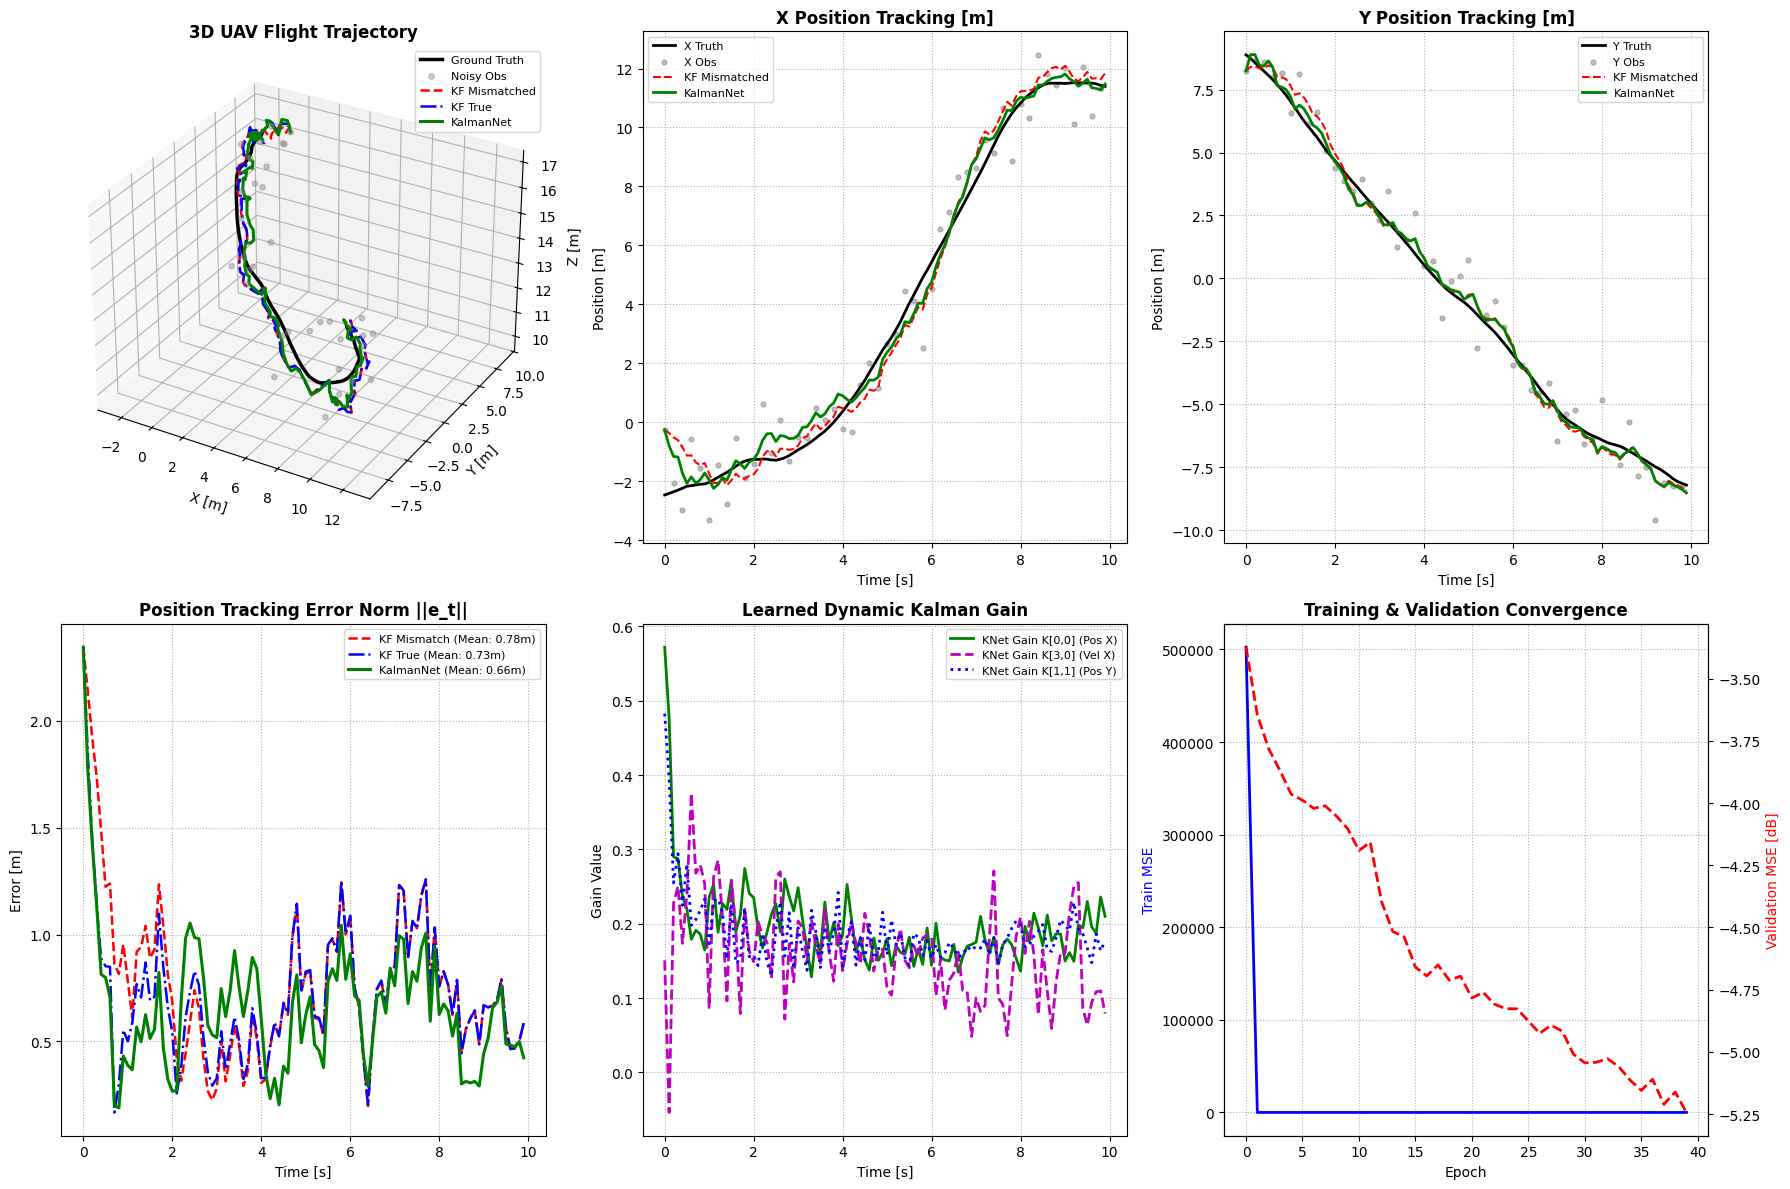

In [9]:
seq_idx = 0
gt = test_X[seq_idx].cpu().numpy()
obs = test_Y[seq_idx].cpu().numpy()
pred_knet = knet_pred[seq_idx].cpu().numpy()
pred_kf_true = kf_true_pred[seq_idx].cpu().numpy()
pred_kf_mismatch = kf_mismatch_pred[seq_idx].cpu().numpy()
kg_traj = knet_KG[seq_idx].cpu().numpy()

fig = plt.figure(figsize=(18, 12))

ax1 = fig.add_subplot(2, 3, 1, projection='3d')
ax1.plot(gt[:, 0], gt[:, 1], gt[:, 2], 'k-', label='Ground Truth', linewidth=2.5)
ax1.scatter(obs[::3, 0], obs[::3, 1], obs[::3, 2], c='gray', alpha=0.4, s=15, label='Noisy Obs')
ax1.plot(pred_kf_mismatch[:, 0], pred_kf_mismatch[:, 1], pred_kf_mismatch[:, 2], 'r--', label='KF Mismatched', linewidth=1.8)
ax1.plot(pred_kf_true[:, 0], pred_kf_true[:, 1], pred_kf_true[:, 2], 'b-.', label='KF True', linewidth=1.8)
ax1.plot(pred_knet[:, 0], pred_knet[:, 1], pred_knet[:, 2], 'g-', label='KalmanNet', linewidth=2.2)
ax1.set_title("3D UAV Flight Trajectory", fontsize=12, fontweight='bold')
ax1.set_xlabel("X [m]")
ax1.set_ylabel("Y [m]")
ax1.set_zlabel("Z [m]")
ax1.legend(loc='upper right', fontsize=8)

ax2 = fig.add_subplot(2, 3, 2)
t_axis = np.arange(gt.shape[0]) * dt
ax2.plot(t_axis, gt[:, 0], 'k-', label='X Truth', linewidth=2)
ax2.scatter(t_axis[::2], obs[::2, 0], c='gray', alpha=0.5, s=12, label='X Obs')
ax2.plot(t_axis, pred_kf_mismatch[:, 0], 'r--', label='KF Mismatched', linewidth=1.5)
ax2.plot(t_axis, pred_knet[:, 0], 'g-', label='KalmanNet', linewidth=2)
ax2.set_title("X Position Tracking [m]", fontsize=12, fontweight='bold')
ax2.set_xlabel("Time [s]")
ax2.set_ylabel("Position [m]")
ax2.grid(True, linestyle=':')
ax2.legend(fontsize=8)

ax3 = fig.add_subplot(2, 3, 3)
ax3.plot(t_axis, gt[:, 1], 'k-', label='Y Truth', linewidth=2)
ax3.scatter(t_axis[::2], obs[::2, 1], c='gray', alpha=0.5, s=12, label='Y Obs')
ax3.plot(t_axis, pred_kf_mismatch[:, 1], 'r--', label='KF Mismatched', linewidth=1.5)
ax3.plot(t_axis, pred_knet[:, 1], 'g-', label='KalmanNet', linewidth=2)
ax3.set_title("Y Position Tracking [m]", fontsize=12, fontweight='bold')
ax3.set_xlabel("Time [s]")
ax3.set_ylabel("Position [m]")
ax3.grid(True, linestyle=':')
ax3.legend(fontsize=8)

ax4 = fig.add_subplot(2, 3, 4)
err_kf_true = np.linalg.norm(pred_kf_true[:, :3] - gt[:, :3], axis=1)
err_kf_mismatch = np.linalg.norm(pred_kf_mismatch[:, :3] - gt[:, :3], axis=1)
err_knet = np.linalg.norm(pred_knet[:, :3] - gt[:, :3], axis=1)
ax4.plot(t_axis, err_kf_mismatch, 'r--', label=f'KF Mismatch (Mean: {err_kf_mismatch.mean():.2f}m)', linewidth=1.8)
ax4.plot(t_axis, err_kf_true, 'b-.', label=f'KF True (Mean: {err_kf_true.mean():.2f}m)', linewidth=1.8)
ax4.plot(t_axis, err_knet, 'g-', label=f'KalmanNet (Mean: {err_knet.mean():.2f}m)', linewidth=2.2)
ax4.set_title("Position Tracking Error Norm ||e_t||", fontsize=12, fontweight='bold')
ax4.set_xlabel("Time [s]")
ax4.set_ylabel("Error [m]")
ax4.grid(True, linestyle=':')
ax4.legend(fontsize=8)

ax5 = fig.add_subplot(2, 3, 5)
ax5.plot(t_axis, kg_traj[:, 0, 0], 'g-', label='KNet Gain K[0,0] (Pos X)', linewidth=2)
ax5.plot(t_axis, kg_traj[:, 3, 0], 'm--', label='KNet Gain K[3,0] (Vel X)', linewidth=2)
ax5.plot(t_axis, kg_traj[:, 1, 1], 'b:', label='KNet Gain K[1,1] (Pos Y)', linewidth=2)
ax5.set_title("Learned Dynamic Kalman Gain", fontsize=12, fontweight='bold')
ax5.set_xlabel("Time [s]")
ax5.set_ylabel("Gain Value")
ax5.grid(True, linestyle=':')
ax5.legend(fontsize=8)

ax6 = fig.add_subplot(2, 3, 6)
ax6.plot(train_losses, 'b-', label='Training MSE', linewidth=2)
ax6.set_ylabel("Train MSE", color='b')
ax6_twin = ax6.twinx()
ax6_twin.plot(val_losses_dB, 'r--', label='Val MSE (dB)', linewidth=2)
ax6_twin.set_ylabel("Validation MSE [dB]", color='r')
ax6.set_title("Training & Validation Convergence", fontsize=12, fontweight='bold')
ax6.set_xlabel("Epoch")
ax6.grid(True, linestyle=':')

plt.tight_layout()
plt.savefig('kalmannet_uav_evaluation.png', dpi=300)
plt.show()


In [10]:
dataset_paths = [
    '/kaggle/input/uav-autonomous-navigation-dataset/uav_navigation_dataset.csv',
    'uav_navigation_dataset.csv',
    r'C:\Users\KIIT0001\.gemini\antigravity\scratch\uav_data\uav_navigation_dataset.csv'
]

uav_csv = None
for p in dataset_paths:
    if os.path.exists(p):
        uav_csv = p
        break

if uav_csv is not None:
    df_uav = pd.read_csv(uav_csv)
    print("Loaded Real UAV Dataset:", uav_csv)
    print("Dataset Shape:", df_uav.shape)
    print(df_uav[['latitude', 'longitude', 'altitude', 'imu_acc_x', 'imu_acc_y', 'imu_acc_z']].head(5))
    
    lat = df_uav['latitude'].values[:500]
    lon = df_uav['longitude'].values[:500]
    alt = df_uav['altitude'].values[:500]
    
    r_earth = 6371000.0
    lat_rad = np.radians(lat)
    lon_rad = np.radians(lon)
    lat0, lon0 = lat_rad[0], lon_rad[0]
    
    pos_x = r_earth * (lon_rad - lon0) * np.cos(lat0)
    pos_y = r_earth * (lat_rad - lat0)
    pos_z = alt - alt[0]
    
    real_pos = np.stack([pos_x, pos_y, pos_z], axis=1)
    noise_sigma = 1.5
    noisy_pos = real_pos + np.random.normal(0, noise_sigma, real_pos.shape)
    
    real_Y_tensor = torch.tensor(noisy_pos[:300], dtype=torch.float32).unsqueeze(0).to(device)
    
    knet_model.eval()
    with torch.no_grad():
        real_knet_est, _ = knet_model.forward_sequence(real_Y_tensor)
        
    real_kf_est, _ = kf_mismatched.filter_sequence(real_Y_tensor[0])
    
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(real_pos[:300, 0], real_pos[:300, 1], 'k-', label='UAV Trajectory', linewidth=2)
    plt.scatter(noisy_pos[:300:4, 0], noisy_pos[:300:4, 1], c='gray', alpha=0.5, s=15, label='GPS Observations')
    plt.plot(real_kf_est[:300, 0].cpu().numpy(), real_kf_est[:300, 1].cpu().numpy(), 'r--', label='KF Mismatched', linewidth=1.8)
    plt.plot(real_knet_est[0, :300, 0].cpu().numpy(), real_knet_est[0, :300, 1].cpu().numpy(), 'g-', label='KalmanNet', linewidth=2.2)
    plt.title("Real UAV Horizontal Flight Track (X-Y)", fontweight='bold')
    plt.xlabel("X [m]")
    plt.ylabel("Y [m]")
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(real_pos[:300, 2], 'k-', label='Altitude Truth', linewidth=2)
    plt.scatter(np.arange(0, 300, 4), noisy_pos[:300:4, 2], c='gray', alpha=0.5, s=15, label='Altitude Obs')
    plt.plot(real_kf_est[:300, 2].cpu().numpy(), 'r--', label='KF Mismatched', linewidth=1.8)
    plt.plot(real_knet_est[0, :300, 2].cpu().numpy(), 'g-', label='KalmanNet', linewidth=2.2)
    plt.title("Real UAV Altitude Tracking (Z)", fontweight='bold')
    plt.xlabel("Time Step")
    plt.ylabel("Altitude [m]")
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.savefig('real_uav_flight_filtering.png', dpi=300)
    plt.show()


In [ ]:
if os.path.exists('__notebook__.ipynb'):
    with open('__notebook__.ipynb', 'r', encoding='utf-8') as f_in:
        nb_data = json.load(f_in)
    with open('KalmanNet_UAV.ipynb', 'w', encoding='utf-8') as f_out:
        json.dump(nb_data, f_out, indent=2)
    print("Saved KalmanNet_UAV.ipynb successfully")

output_files = [f for f in os.listdir('.') if os.path.isfile(f)]
print("Generated Output Files:")
for f in sorted(output_files):
    sz = os.path.getsize(f)
    print(f" - {f} ({sz:,} bytes)")
